In [1]:
from findingampa.utils.tm3d import calc_3dtm, fit_gaussian_3d_list, Gaussian3DList
import mrcfile
from pytom_tm.tmjob import TMJob
from pytom_tm.parallel import run_job_parallel
from findingampa.utils.assets import FA_ASSETS
from pathlib import Path
from skimage.feature import peak_local_max
import torch
import numpy as np
from torch_subpixel_crop import subpixel_crop_3d
import matplotlib.pyplot as plt

In [2]:
tomo = Path("/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1_tomograms/TOP_TOMOS/20230512-EG18pos2_80/best_alignment/20230512-EG18pos2_80_full_rec_BP_flat.mrc")
tmfolder = Path('./') / "TM"
tmfolder.mkdir(exist_ok=True)
job = TMJob(
    "0",
    20,
    tomo,
    FA_ASSETS / "templates" / "aunp01" / "temaplte.mrc",
    FA_ASSETS / "templates" / "aunp01" / "mask.mrc",
    tmfolder,
    angle_increment=str(FA_ASSETS / "templates" / "aunp01" / "angles.txt"),
    mask_is_spherical=True,
    tilt_angles=[-48,48],
    tilt_weighting=None,
    search_x=None,
    search_y=None,
    search_z=None,
    tomogram_mask=None,
    voxel_size=10.0,
    low_pass=None,
    high_pass=None,
    dose_accumulation=None,
    ctf_data=None,
    whiten_spectrum=True,
    rotational_symmetry=1,
    particle_diameter=None,
    random_phase_correction=False,
    rng_seed=5,
)

score_volume, angle_volume = run_job_parallel(
    job, (2,2,2), [0]
)

Progress job_00 on device 0:


100%|██████████| 1/1 [00:00<00:00,  5.23it/s]


Progress job_01 on device 0:


100%|██████████| 1/1 [00:00<00:00, 1146.61it/s]


Progress job_02 on device 0:


100%|██████████| 1/1 [00:00<00:00, 1176.85it/s]


... (6 outputs left out)

Progress job_06 on device 0:


100%|██████████| 1/1 [00:00<00:00, 1197.00it/s]


Progress job_07 on device 0:


100%|██████████| 1/1 [00:00<00:00, 1168.66it/s]


In [3]:
peaks = peak_local_max(score_volume, min_distance=2, threshold_abs=0.3, exclude_border=10)

locations_tomo = torch.Tensor(peaks[:,::-1].copy()+ np.array([0,0,0]))

In [4]:
with mrcfile.open(tomo, permissive=True) as f:
    tomo_tensor = torch.tensor(f.data)

In [5]:
boxes = subpixel_crop_3d(tomo_tensor, locations_tomo, 8)

In [6]:
tomo_fitted_params_list = fit_gaussian_3d_list(tomo_tensor.cuda(), locations_tomo.int().cuda(), 8, sign=-1)

/home/gouauxlab/andecath/env/lib/python3.11/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3595.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [10]:
boxsize = 8 
coords = torch.stack(torch.meshgrid(
        torch.arange(boxsize),
        torch.arange(boxsize),
        torch.arange(boxsize)
    ), dim=-1).reshape(-1, 3).to(tomo_tensor.device) - torch.tensor([boxsize//2, boxsize//2, boxsize//2], device=tomo_tensor.device)
x_coords = coords[:, 2].float()
y_coords = coords[:, 1].float()
z_coords = coords[:, 0].float()

model = Gaussian3DList(len(locations_tomo),sign=-1).to(tomo_tensor.device)
model.amplitude.data = torch.tensor([p['amplitude'] for p in tomo_fitted_params_list], device=tomo_tensor.device)
model.x0.data = torch.tensor([p['x0'] for p in tomo_fitted_params_list], device=tomo_tensor.device)
model.y0.data = torch.tensor([p['y0'] for p in tomo_fitted_params_list], device=tomo_tensor.device)
model.z0.data = torch.tensor([p['z0'] for p in tomo_fitted_params_list], device=tomo_tensor.device)
model.sigma_x.data = torch.tensor([p['sigma_x'] for p in tomo_fitted_params_list], device=tomo_tensor.device)
model.sigma_y.data = torch.tensor([p['sigma_y'] for p in tomo_fitted_params_list], device=tomo_tensor.device)
model.sigma_z.data = torch.tensor([p['sigma_z'] for p in tomo_fitted_params_list], device=tomo_tensor.device)
gauss = model(x_coords, y_coords, z_coords).reshape(len(locations_tomo), boxsize, boxsize, boxsize)

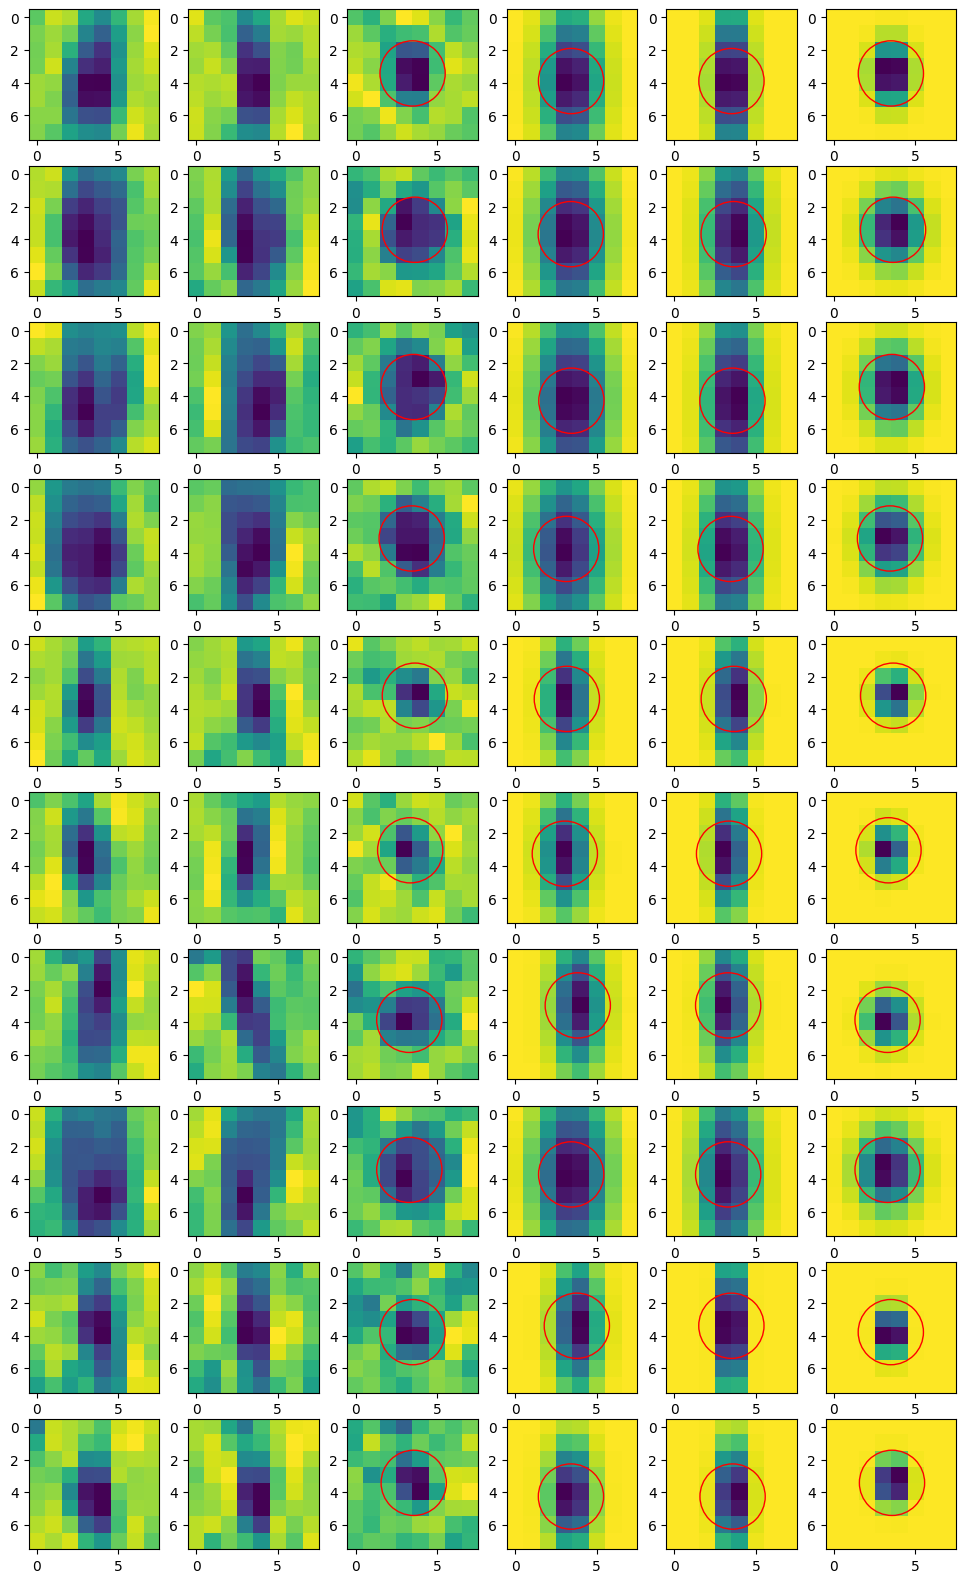

In [12]:
# plot 3 x 10 plots with minip alogn each axis of the first 10 boxes
plt.figure(figsize=(12,20))
center = np.array([4,4])
for i in range(10):
    plt.subplot(10,6,i*6+1)
    plt.imshow(boxes[i].detach().numpy().min(axis=2))
    
    plt.subplot(10,6,i*6+2)
    plt.imshow(boxes[i].detach().numpy().min(axis=1))
    plt.subplot(10,6,i*6+3)
    plt.imshow(boxes[i].detach().numpy().min(axis=0))
    # Draw circle around center
    circle = plt.Circle(center + np.array([
        tomo_fitted_params_list[i]['x0'],
        tomo_fitted_params_list[i]['y0'],
    ]), 2, color='r', fill=False)
    plt.gca().add_artist(circle)
    plt.subplot(10,6,i*6+4)
    plt.imshow(gauss[i].detach().numpy().min(axis=2))
    # Draw circle around center
    circle = plt.Circle(center + np.array([
        tomo_fitted_params_list[i]['y0'],
        tomo_fitted_params_list[i]['z0'],
    ]), 2, color='r', fill=False)
    plt.gca().add_artist(circle)
    plt.subplot(10,6,i*6+5)
    plt.imshow(gauss[i].detach().numpy().min(axis=1))
    # Draw circle around center
    circle = plt.Circle(center + np.array([
        tomo_fitted_params_list[i]['x0'],
        tomo_fitted_params_list[i]['z0'],
    ]), 2, color='r', fill=False)
    plt.gca().add_artist(circle)
    plt.subplot(10,6,i*6+6)
    plt.imshow(gauss[i].detach().numpy().min(axis=0))
    # Draw circle around center
    circle = plt.Circle(center + np.array([
        tomo_fitted_params_list[i]['x0'],
        tomo_fitted_params_list[i]['y0'],
    ]), 2, color='r', fill=False)
    plt.gca().add_artist(circle)

In [9]:
model(.amplitude.data = torch.ones(len(locations_tomo))*5)

SyntaxError: invalid syntax (2645065502.py, line 1)

In [49]:
model.amplitude

Parameter containing:
tensor([5., 5., 5.,  ..., 5., 5., 5.], requires_grad=True)